In [2]:
# %pip install pandas numpy matplotlib scipy seaborn scikit-learn 
# DATA ANALYTICS - LIBRARY IMPORTS

# Data manipulation and analysis
import pandas as pd
# pd: Load CSV/Excel files, clean data, filter rows,
# join tables, group data, and handle missing values.

# Numerical computing
import numpy as np
# np: Arrays, mathematical operations, statistical
# calculations, and numerical transformations.

# Data visualization
import matplotlib
import matplotlib.pyplot as plt
# plt: Create line charts, bar charts, histograms,
# scatter plots, and customize chart layouts.

# Scientific and statistical computing
import scipy
# scipy: Statistical tests, probability distributions,
# optimization, and scientific calculations.

# Statistical data visualization
import seaborn as sns
# sns: Statistical charts, heatmaps, boxplots,
# distributions, and correlation visualizations.

# Machine learning
import sklearn
# sklearn: Data preprocessing, feature engineering,
# model training, model selection, and evaluation.

# Statistical modeling and inference
import statsmodels as sm

# File and directory paths
from pathlib import Path
# Path: Manage file paths across operating systems.

In [3]:
# Verify the installed library versions
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("SciPy version:", scipy.__version__)
print("Matplotlib version:", matplotlib.__version__)
print("Seaborn version:", sns.__version__)
print("Scikit-learn version:", sklearn.__version__)
print("Statsmodels version:", sm.__version__)

# pathlib is part of Python's standard library;
# it does not have a package version attribute like these libraries.
print("Path class imported:", Path)


Pandas version: 3.0.3
NumPy version: 2.4.6
SciPy version: 1.17.1
Matplotlib version: 3.11.0
Seaborn version: 0.13.2
Scikit-learn version: 1.9.0
Statsmodels version: 0.14.6
Path class imported: <class 'pathlib.Path'>


In [4]:
# create a datframe of the csv file
df = pd.read_csv(r"C:\Users\vasav\OneDrive\Desktop\DA_PROJECTS\Project_2\Online Retail DATA ANALYTICS - Copy.csv")

In [12]:
# To check how many rows and columns
print("Number of rows and columns:", df.shape)

Number of rows and columns: (541909, 8)


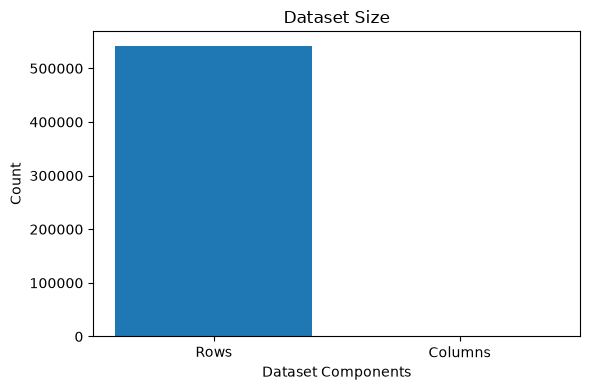

In [13]:
# Get the number of rows and columns
total_rows, total_columns = df.shape

# Create a bar chart
plt.figure(figsize=(6, 4))
plt.bar(
    ["Rows", "Columns"],
    [total_rows, total_columns]
)

plt.title("Dataset Size")
plt.ylabel("Count")
plt.xlabel("Dataset Components")
plt.tight_layout()
plt.show()

In [14]:
# To Print Columns Name
print("The columns names are :-", df.columns.tolist())

The columns names are :- ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


In [15]:
# To check DataTypes and Non-null Count
print("Info about the df", df.info())

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  str    
 1   StockCode    541909 non-null  str    
 2   Description  540455 non-null  str    
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  str    
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 67.8 MB
Info about the df None


In [16]:
#need type conversation of InvoiceDate str to date and time
# Convert InvoiceDate from string to datetime
df["InvoiceDate"] = pd.to_datetime(
    df["InvoiceDate"],
    format="%d-%m-%Y %H:%M"
)

# Check the data type
print(df["InvoiceDate"].dtype)

# Display the date and time
display(df[["InvoiceDate"]].head())

datetime64[us]


,InvoiceDate
0,2010-12-01 08:26:00
1,2010-12-01 08:26:00
2,2010-12-01 08:26:00
3,2010-12-01 08:26:00
4,2010-12-01 08:26:00


In [10]:
# for the particular columns
Count_null = df["CustomerID"].isna().sum()
print("Total null count ", Count_null)

Total null count  135080


In [11]:
# Count the null and its percentage using function
def null_summary(series):
    #count the nulls in series
    count_null = series.isnull().sum()
    #calculate percentage of null values in series
    null_percentage = (
    (count_null / len(series)) * 100 
     if len(series) > 0 else 0
    )
    #calculate not null 
    count_notnull = series.notna().sum()
    #calculate percentage of not null values in series
    notnull_percentage = (
    (count_notnull / len(series)) * 100 
     if len(series) > 0 else 0
    )
    return pd.Series({
    "Total null count is" : count_null,
    "Percentage of null is" : round(null_percentage, 2),
    "Total not null count is" : count_notnull,
    "Percentage of not null is" : round(notnull_percentage, 2)
    })

In [12]:
#apply the null_summary for every columns
null_apply = df.apply(null_summary)
#transform the each columns to row 
null_apply = null_apply.T
#display the null summary 
display(null_apply)

,Total null count is,Percentage of null is,Total not null count is,Percentage of not null is
InvoiceNo,0.0,0.00,541909.0,100.00
StockCode,0.0,0.00,541909.0,100.00
Description,1454.0,0.27,540455.0,99.73
Quantity,0.0,0.00,541909.0,100.00
InvoiceDate,0.0,0.00,541909.0,100.00
UnitPrice,0.0,0.00,541909.0,100.00
CustomerID,135080.0,24.93,406829.0,75.07
Country,0.0,0.00,541909.0,100.00


In [13]:
#total null and it's percentage
total_nulls = df.isna().sum().sum()
total_nulls_percentage = ((total_nulls / df.size * 100))
print("total null values in cells -----> ",total_nulls)
print("total null values in cells percentage-----> ",total_nulls_percentage)

total null values in cells ----->  136534
total null values in cells percentage----->  3.149375633178264


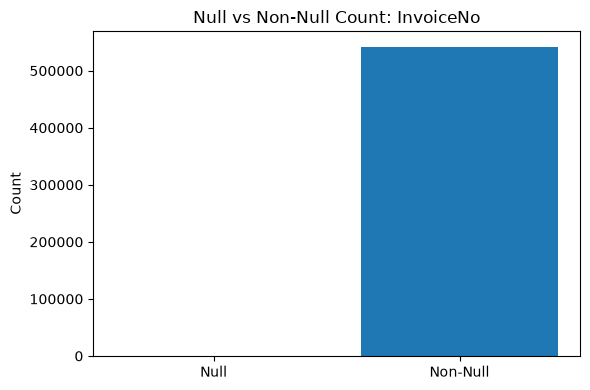

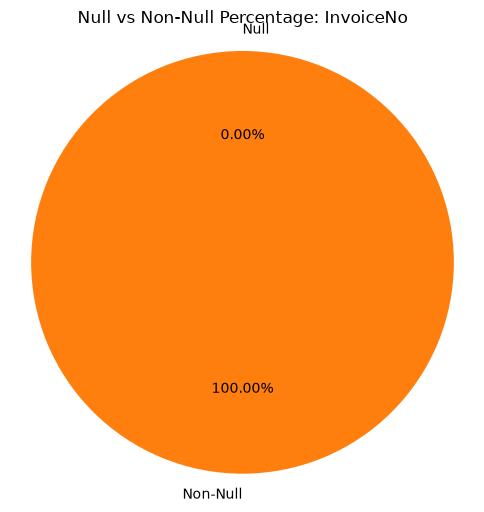

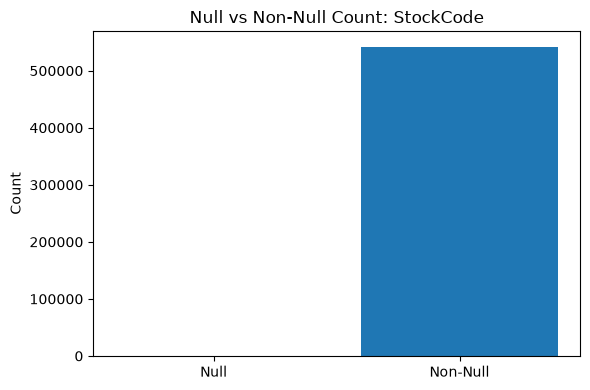

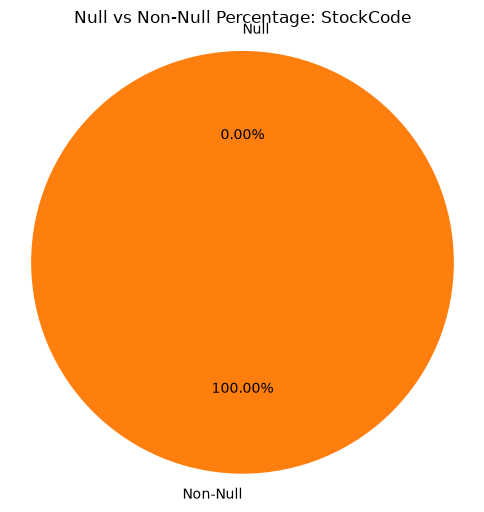

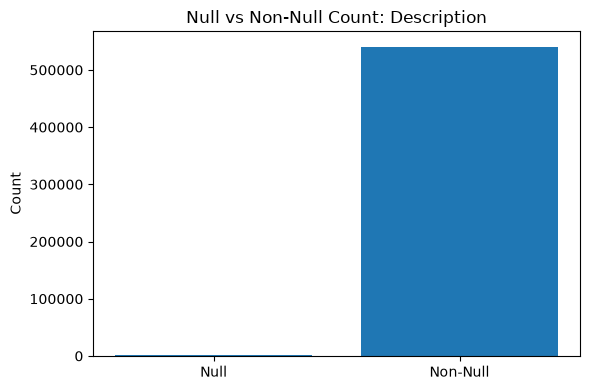

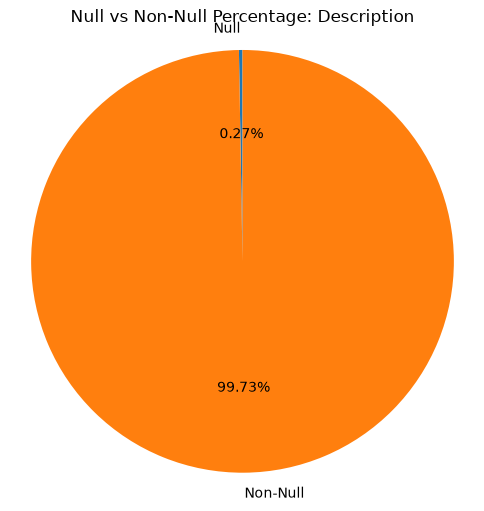

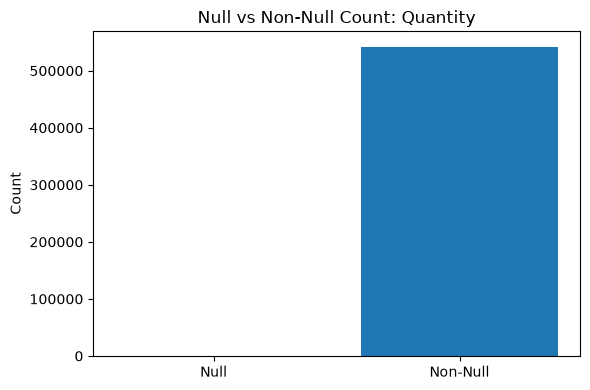

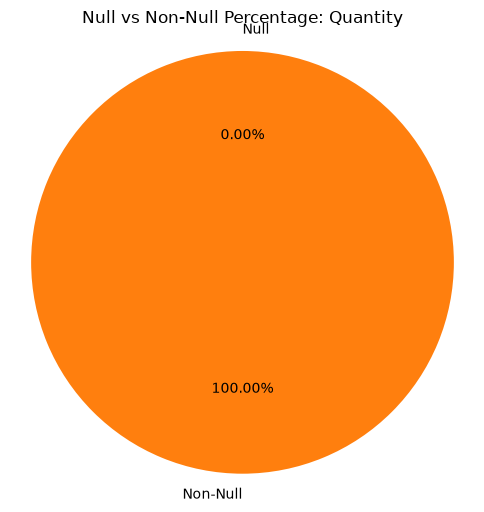

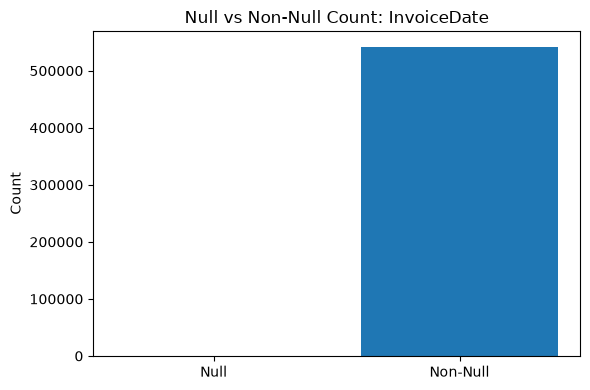

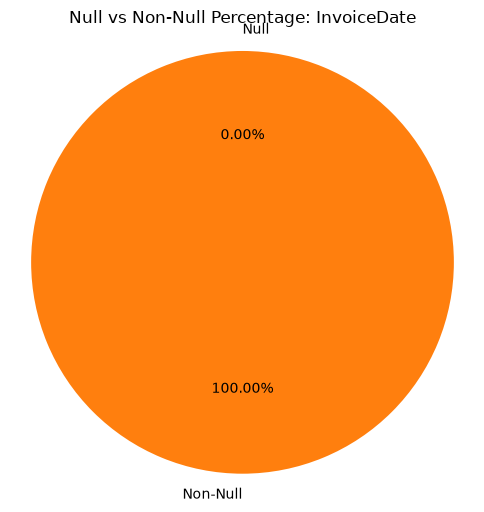

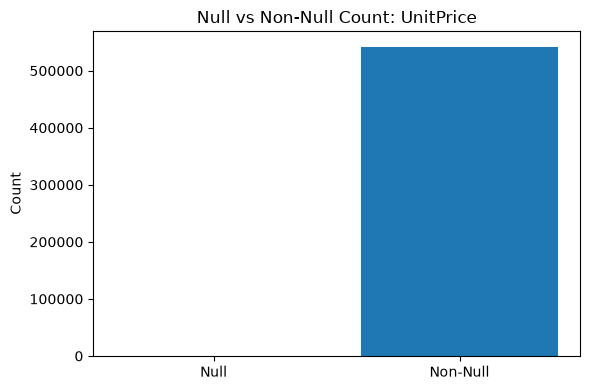

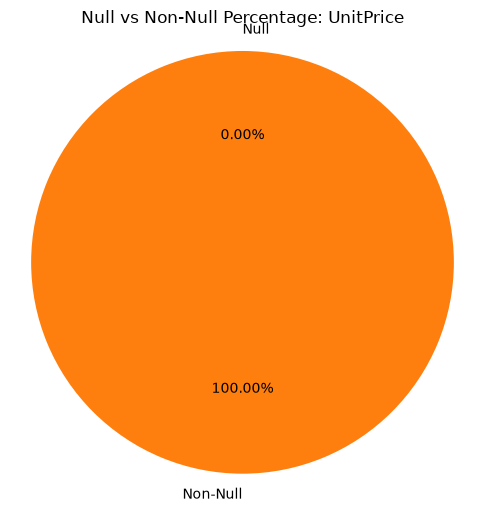

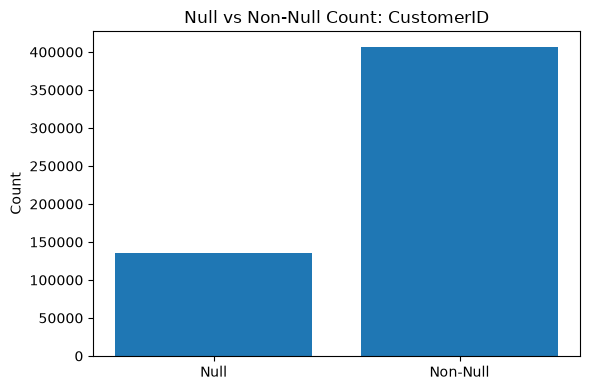

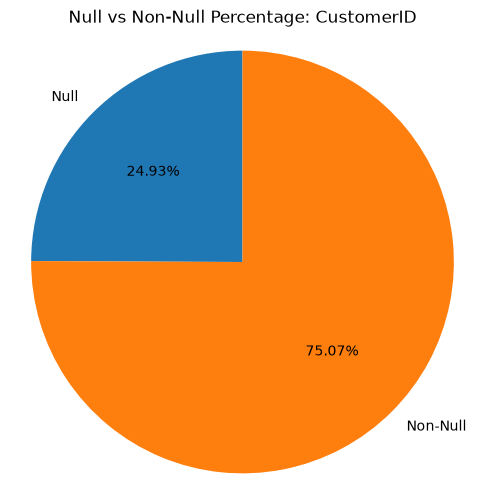

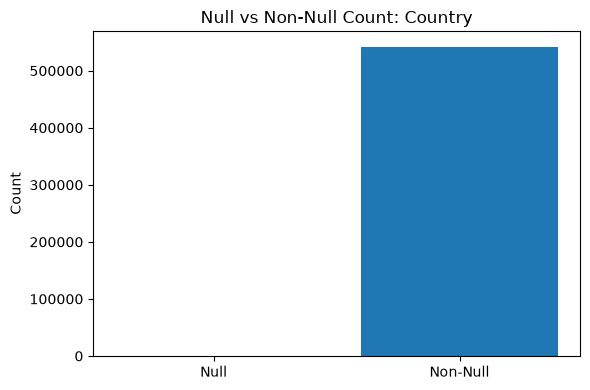

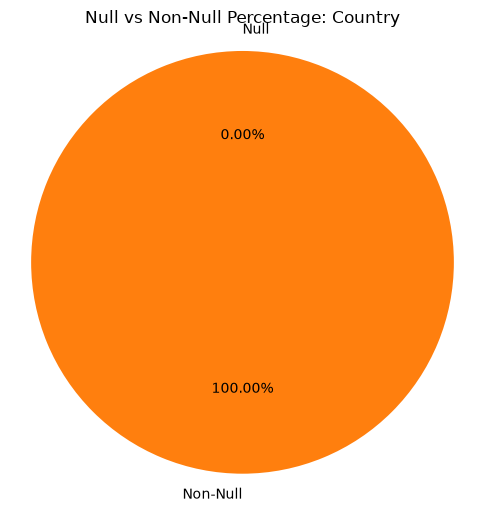

In [14]:
#chart using matplotlib.pyplot as plt
# Apply the null analysis function to every column
null_apply = df.apply(null_summary).T

# Rename columns to standard names
null_apply.columns = [
    "Null_Count",
    "Null_Percentage",
    "Non_Null_Count",
    "Non_Null_Percentage"
]

# Loop through every column and create its charts
for column in null_apply.index:

    # Get null and non-null counts for this column
    null_count = null_apply.loc[column, "Null_Count"]
    non_null_count = null_apply.loc[column, "Non_Null_Count"]

    # Get null and non-null percentages for this column
    null_percentage = null_apply.loc[column, "Null_Percentage"]
    non_null_percentage = null_apply.loc[column, "Non_Null_Percentage"]
    
    # CHART 1: BAR CHART - COUNTS-
    plt.figure(figsize=(6, 4))

    plt.bar(
        ["Null", "Non-Null"],
        [null_count, non_null_count]
    )

    plt.title(f"Null vs Non-Null Count: {column}")
    plt.ylabel("Count")
    plt.tight_layout()
    plt.show()

    # CHART 2: PIE CHART - PERCENTAGES

    plt.figure(figsize=(6, 6))

    if null_count + non_null_count == 0:
        # Handle an empty Series without dividing by zero
        plt.title(f"No Data Available: {column}")
        plt.axis("off")
    else:
        plt.pie(
            [null_percentage, non_null_percentage],
            labels=["Null", "Non-Null"],
            autopct="%1.2f%%",
            startangle=90
        )

        plt.title(f"Null vs Non-Null Percentage: {column}")
        plt.axis("equal")

    plt.show()


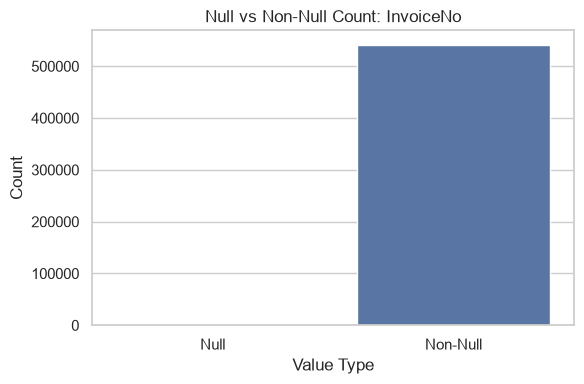

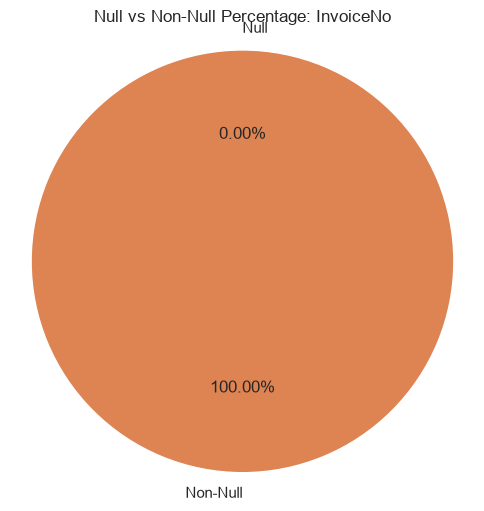

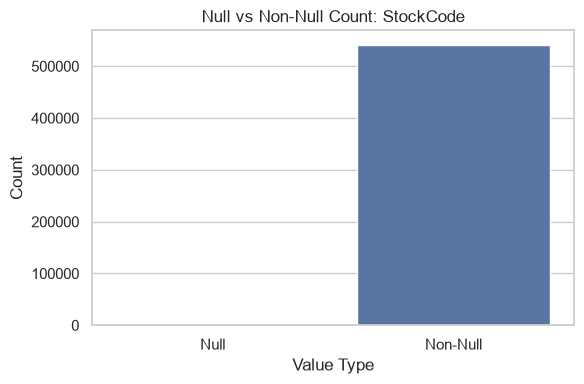

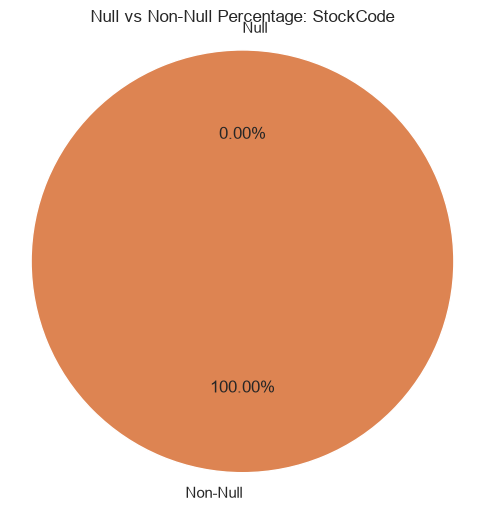

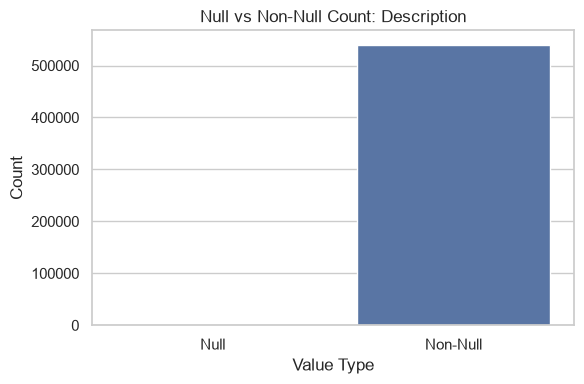

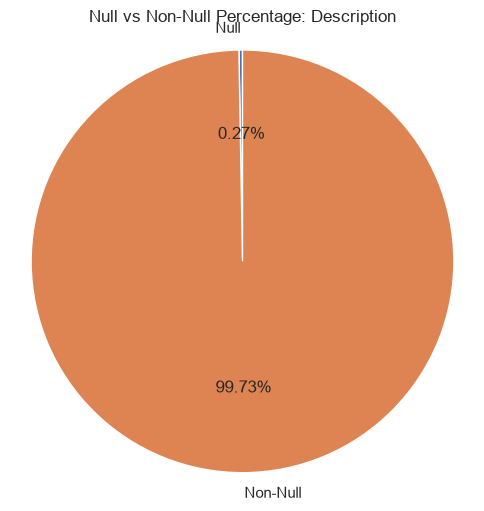

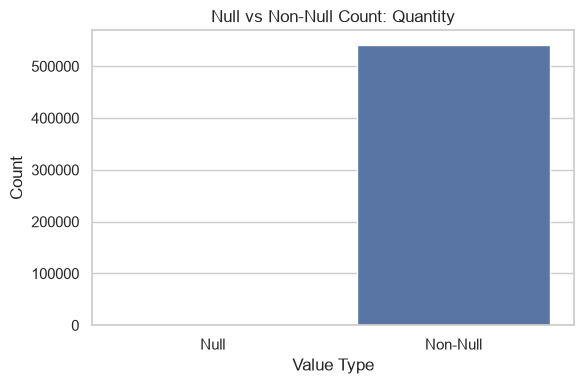

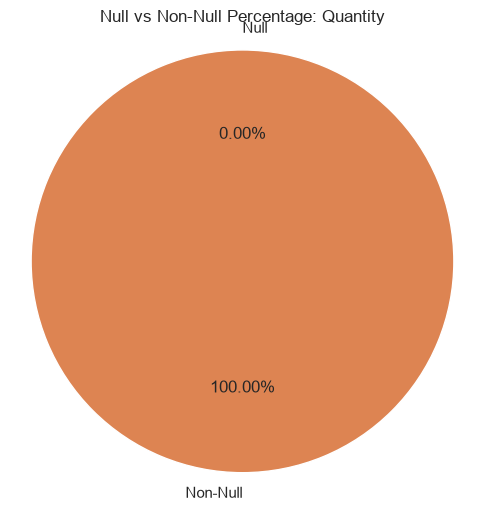

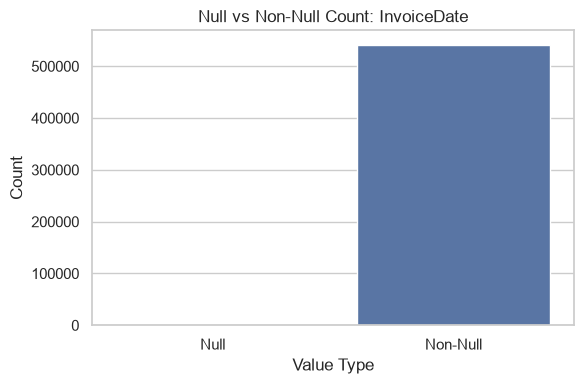

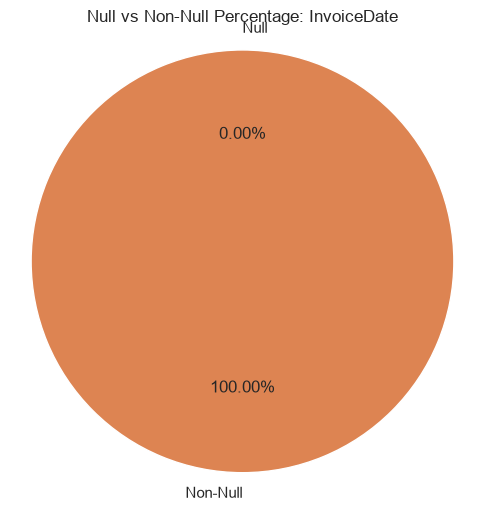

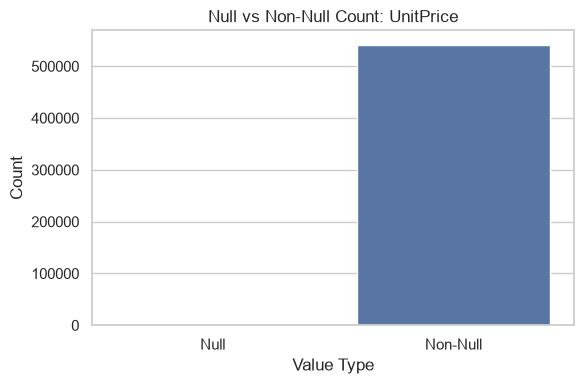

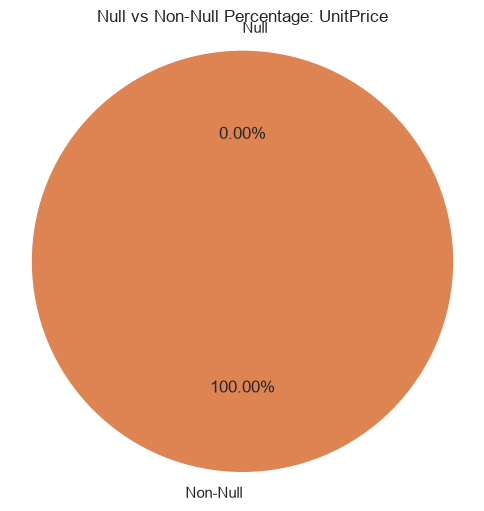

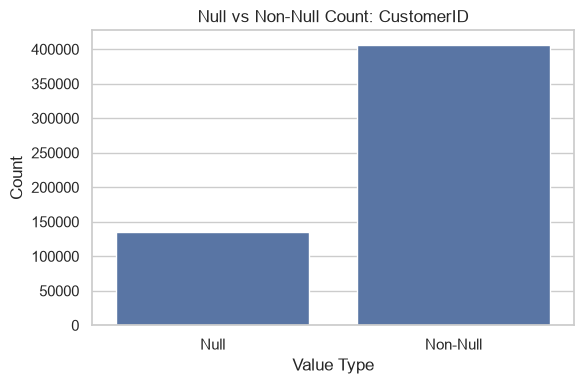

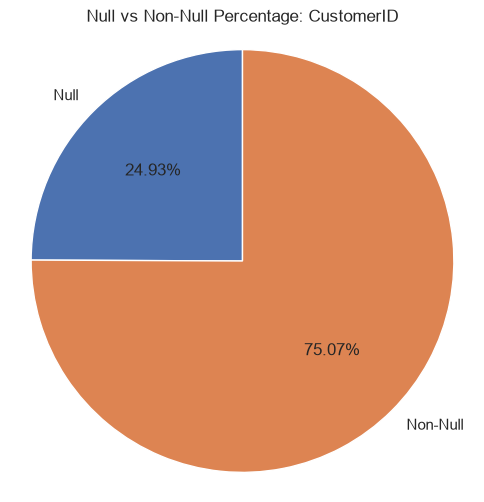

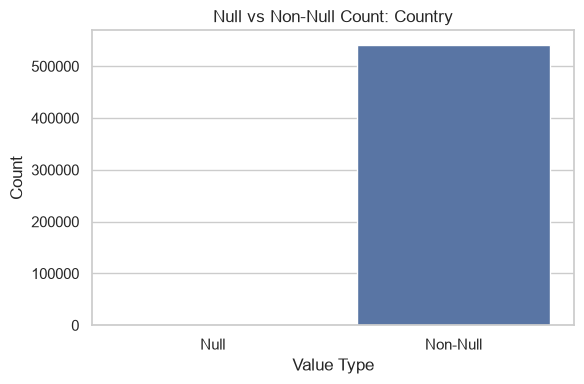

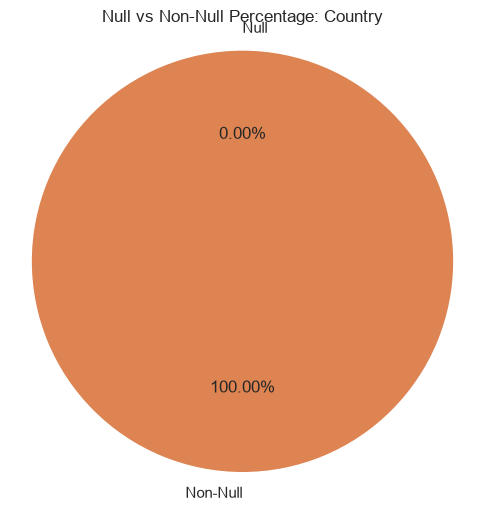

In [15]:
# Set the Seaborn chart theme
sns.set_theme(style="whitegrid")

# Apply null analysis to every DataFrame column
null_apply = df.apply(null_summary).T

# Rename columns for consistency
null_apply.columns = [
    "Null_Count",
    "Null_Percentage",
    "Non_Null_Count",
    "Non_Null_Percentage"
]

# Loop through every column
for column in null_apply.index:

    # Extract null and non-null counts
    null_count = null_apply.loc[column, "Null_Count"]
    non_null_count = null_apply.loc[column, "Non_Null_Count"]

    # Extract null and non-null percentages
    null_percentage = null_apply.loc[column, "Null_Percentage"]
    non_null_percentage = null_apply.loc[column, "Non_Null_Percentage"]

    # Prepare data for plotting
    chart_data = pd.DataFrame({
        "Value_Type": ["Null", "Non-Null"],
        "Count": [null_count, non_null_count]
    })

    # CHART 1: SEABORN BAR CHART

    plt.figure(figsize=(6, 4))

    sns.barplot(
        data=chart_data,
        x="Value_Type",
        y="Count"
    )

    plt.title(f"Null vs Non-Null Count: {column}")
    plt.xlabel("Value Type")
    plt.ylabel("Count")
    plt.tight_layout()
    plt.show()

    # CHART 2: PIE CHART
    # Matplotlib is required for this chart
    if null_count + non_null_count > 0:

        plt.figure(figsize=(6, 6))

        plt.pie(
            [null_percentage, non_null_percentage],
            labels=["Null", "Non-Null"],
            autopct="%1.2f%%",
            startangle=90
        )

        plt.title(f"Null vs Non-Null Percentage: {column}")
        plt.axis("equal")
        plt.show()


In [16]:
#for particular columns data view of top 
df['Country'].head(100)

0     United Kingdom
1     United Kingdom
2     United Kingdom
3     United Kingdom
4     United Kingdom
           ...      
95    United Kingdom
96    United Kingdom
97    United Kingdom
98    United Kingdom
99    United Kingdom
Name: Country, Length: 100, dtype: str

In [17]:
#for particular columns data view of bottom
df['Country'].tail(100)

541809    United Kingdom
541810    United Kingdom
541811    United Kingdom
541812    United Kingdom
541813    United Kingdom
               ...      
541904            France
541905            France
541906            France
541907            France
541908            France
Name: Country, Length: 100, dtype: str

In [18]:
#function to view top 500, middle 500 and bottom 500 
def view_500(series):
    print(f"Column name is : {series.name}")
    #view top 500 raws
    display(series.head(500))
    #view  middle 500 raws
    middle_position = max(0, (len(series) // 2) - 500)
    display(series.iloc[middle_position : middle_position + 500])
    #view bottom 500 values
    display(series.tail(500))

In [19]:
#applying function to all columns 
for columns in df.columns:
    view_500(df[columns])

Column name is : InvoiceNo


0      536365
1      536365
2      536365
3      536365
4      536365
        ...  
495    536409
496    536409
497    536409
498    536409
499    536409
Name: InvoiceNo, Length: 500, dtype: str

270454    560568
270455    560568
270456    560568
270457    560568
270458    560568
           ...  
270949    560601
270950    560601
270951    560601
270952    560601
270953    560601
Name: InvoiceNo, Length: 500, dtype: str

541409    581498
541410    581498
541411    581498
541412    581498
541413    581498
           ...  
541904    581587
541905    581587
541906    581587
541907    581587
541908    581587
Name: InvoiceNo, Length: 500, dtype: str

Column name is : StockCode


...

541409        NaN
541410        NaN
541411        NaN
541412        NaN
541413        NaN
           ...   
541904    12680.0
541905    12680.0
541906    12680.0
541907    12680.0
541908    12680.0
Name: CustomerID, Length: 500, dtype: float64

Column name is : Country


0      United Kingdom
1      United Kingdom
2      United Kingdom
3      United Kingdom
4      United Kingdom
            ...      
495    United Kingdom
496    United Kingdom
497    United Kingdom
498    United Kingdom
499    United Kingdom
Name: Country, Length: 500, dtype: str

270454    United Kingdom
270455    United Kingdom
270456    United Kingdom
270457    United Kingdom
270458    United Kingdom
               ...      
270949    United Kingdom
270950    United Kingdom
270951    United Kingdom
270952    United Kingdom
270953    United Kingdom
Name: Country, Length: 500, dtype: str

541409    United Kingdom
541410    United Kingdom
541411    United Kingdom
541412    United Kingdom
541413    United Kingdom
               ...      
541904            France
541905            France
541906            France
541907            France
541908            France
Name: Country, Length: 500, dtype: str

In [20]:
#to fet the count of the uniue values 
def unique_value(series):
    display(series.nunique())
unique_value(df["Country"])

38

In [21]:
#to view the unique value for one series 
df.Country.unique()

<ArrowStringArray>
[      'United Kingdom',               'France',            'Australia',
          'Netherlands',              'Germany',               'Norway',
                 'EIRE',          'Switzerland',                'Spain',
               'Poland',             'Portugal',                'Italy',
              'Belgium',            'Lithuania',                'Japan',
              'Iceland',      'Channel Islands',              'Denmark',
               'Cyprus',               'Sweden',              'Austria',
               'Israel',              'Finland',              'Bahrain',
               'Greece',            'Hong Kong',            'Singapore',
              'Lebanon', 'United Arab Emirates',         'Saudi Arabia',
       'Czech Republic',               'Canada',          'Unspecified',
               'Brazil',                  'USA',   'European Community',
                'Malta',                  'RSA']
Length: 38, dtype: str

In [22]:
#to view the unique values and it's count function
def unique_value_count(series):
    print("The unique_values and its counts -----> ", series.value_counts())
    print("No count of unique_values -----> ",series.nunique())
for Column in df.columns:
    unique_value_count(df[Column])

The unique_values and its counts ----->  InvoiceNo
573585     1114
581219      749
581492      731
580729      721
558475      705
           ... 
581487        1
581491        1
C581499       1
581566        1
C581568       1
Name: count, Length: 25900, dtype: int64
No count of unique_values ----->  25900
The unique_values and its counts ----->  StockCode
85123A    2313
22423     2203
85099B    2159
47566     1727
20725     1639
          ... 
23609        1
85179a       1
23617        1
90214U       1
47591b       1
Name: count, Length: 4070, dtype: int64
No count of unique_values ----->  4070
The unique_values and its counts ----->  Description
WHITE HANGING HEART T-LIGHT HOLDER    2369
REGENCY CAKESTAND 3 TIER              2200
JUMBO BAG RED RETROSPOT               2159
PARTY BUNTING                         1727
LUNCH BAG RED RETROSPOT               1638
                                      ... 
LETTER "U" BLING KEY RING                1
wet                                      1


In [23]:
# duplicated count and in percentage 
def duplicated_count(series):
    print("The exact duplicated count", series.duplicated().sum())
    print("The percentage of duplicated", (series.duplicated().sum() / len(df)) * 100) 
# for Columns_1 in df.columns:
# duplicated_count(df[Columns_1])
duplicated_count(df)

The exact duplicated count 5268
The percentage of duplicated 0.9721189350979592


In [7]:
def duplicated_records(series):
    display(series[series.duplicated()])
duplicated_records(df)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,01-12-2010 11:45,1.25,17908.0,United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,01-12-2010 11:45,2.10,17908.0,United Kingdom
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,01-12-2010 11:45,2.95,17908.0,United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,01-12-2010 11:45,4.95,17908.0,United Kingdom
555,536412,22327,ROUND SNACK BOXES SET OF 4 SKULLS,1,01-12-2010 11:49,2.95,17920.0,United Kingdom
...,...,...,...,...,...,...,...,...
541675,581538,22068,BLACK PIRATE TREASURE CHEST,1,09-12-2011 11:34,0.39,14446.0,United Kingdom
541689,581538,23318,BOX OF 6 MINI VINTAGE CRACKERS,1,09-12-2011 11:34,2.49,14446.0,United Kingdom
541692,581538,22992,REVOLVER WOODEN RULER,1,09-12-2011 11:34,1.95,14446.0,United Kingdom
541699,581538,22694,WICKER STAR,1,09-12-2011 11:34,2.10,14446.0,United Kingdom


In [11]:
# FUNCTION: VIEW EXACT DUPLICATE PAIRS SIDE-BY-SIDE
def duplicated_count(data_obj):
    
    # 1. Count only the extra copies (how many rows would be removed on drop_duplicates)
    extra_dup_count = data_obj.duplicated(keep="first").sum()
    extra_dup_pct = (extra_dup_count / len(data_obj)) * 100 if len(data_obj) > 0 else 0
    
    # 2. Count all rows involved in duplicates (Original row + Duplicate copy)
    all_involved_count = data_obj.duplicated(keep=False).sum()
    
    print("Extra duplicate copies count (keep='first') -----> ", extra_dup_count)
    print("Percentage of extra duplicate copies        -----> ", round(extra_dup_pct, 2), "%")
    print("Total rows in duplicate pairs (keep=False)  -----> ", all_involved_count)
    
    # 3. Extract BOTH the original row and its exact duplicate copy (keep=False)
    duplicate_pairs = data_obj[data_obj.duplicated(keep=False)]
    
    # 4. Sort so identical rows sit directly above/below each other
    if isinstance(data_obj, pd.DataFrame):
        duplicate_pairs = duplicate_pairs.sort_values(by=list(data_obj.columns))
    else:
        duplicate_pairs = duplicate_pairs.sort_values()
        
    print("\n--- EXACT DUPLICATE ROWS (ORIGINAL + COPY SIDE-BY-SIDE) ---")
    display(duplicate_pairs.head(10))
    display(duplicate_pairs.tail(10))
    # display(duplicate_pairs)
# Run on the entire DataFrame
duplicated_count(df)

Extra duplicate copies count (keep='first') ----->  5268
Percentage of extra duplicate copies        ----->  0.97 %
Total rows in duplicate pairs (keep=False)  ----->  10147

--- EXACT DUPLICATE ROWS (ORIGINAL + COPY SIDE-BY-SIDE) ---


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
494,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,01-12-2010 11:45,1.25,17908.0,United Kingdom
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,01-12-2010 11:45,1.25,17908.0,United Kingdom
485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,01-12-2010 11:45,4.95,17908.0,United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,01-12-2010 11:45,4.95,17908.0,United Kingdom
489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,01-12-2010 11:45,2.10,17908.0,United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,01-12-2010 11:45,2.10,17908.0,United Kingdom
521,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,01-12-2010 11:45,2.95,17908.0,United Kingdom
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,01-12-2010 11:45,2.95,17908.0,United Kingdom
578,536412,21448,12 DAISY PEGS IN WOOD BOX,1,01-12-2010 11:49,1.65,17920.0,United Kingdom
598,536412,21448,12 DAISY PEGS IN WOOD BOX,1,01-12-2010 11:49,1.65,17920.0,United Kingdom


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
411643,C572226,85066,CREAM SWEETHEART MINI CHEST,-1,21-10-2011 13:58,12.75,15321.0,United Kingdom
411644,C572226,85066,CREAM SWEETHEART MINI CHEST,-1,21-10-2011 13:58,12.75,15321.0,United Kingdom
436250,C574095,22326,ROUND SNACK BOXES SET OF4 WOODLAND,-1,03-11-2011 09:54,2.95,12674.0,France
436251,C574095,22326,ROUND SNACK BOXES SET OF4 WOODLAND,-1,03-11-2011 09:54,2.95,12674.0,France
440148,C574510,22360,GLASS JAR ENGLISH CONFECTIONERY,-1,04-11-2011 13:25,2.95,15110.0,United Kingdom
440149,C574510,22360,GLASS JAR ENGLISH CONFECTIONERY,-1,04-11-2011 13:25,2.95,15110.0,United Kingdom
461407,C575940,23309,SET OF 60 I LOVE LONDON CAKE CASES,-24,13-11-2011 11:38,0.55,17838.0,United Kingdom
461408,C575940,23309,SET OF 60 I LOVE LONDON CAKE CASES,-24,13-11-2011 11:38,0.55,17838.0,United Kingdom
529980,C580764,22667,RECIPE BOX RETROSPOT,-12,06-12-2011 10:38,2.95,14562.0,United Kingdom
529981,C580764,22667,RECIPE BOX RETROSPOT,-12,06-12-2011 10:38,2.95,14562.0,United Kingdom
